In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import calendar

# Raiz do projeto
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Arquivos
ARQUIVO_BASE = (
    ROOT / "data" / "processed" /
    "meteorologia" / "meteorologia_baixada_limpa.csv"
)

PASTA_REPORTS = ROOT / "reports" / "meteorologia"
PASTA_REPORTS.mkdir(parents=True, exist_ok=True)

# Estilo dos gráficos
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 110

print("Raiz:", ROOT)
print("Base encontrada:", ARQUIVO_BASE.exists())

Raiz: c:\Users\Lenovo\Desktop\porto-santos
Base encontrada: True


In [2]:
if not ARQUIVO_BASE.exists():
    raise FileNotFoundError(
        "Execute primeiro o pipeline.py para gerar a base limpa."
    )

df = pd.read_csv(ARQUIVO_BASE)

df["data_hora_utc"] = pd.to_datetime(
    df["data_hora_utc"],
    utc=True,
    errors="coerce"
)

df = df.dropna(subset=["data_hora_utc"]).copy()

df["ano"] = df["data_hora_utc"].dt.year
df["mes"] = df["data_hora_utc"].dt.month
df["nome_mes"] = df["mes"].map(
    lambda x: calendar.month_abbr[x]
)
df["dia"] = df["data_hora_utc"].dt.day
df["hora"] = df["data_hora_utc"].dt.hour

print("Dimensões:", df.shape)
print("Período:", df["data_hora_utc"].min(),
      "até", df["data_hora_utc"].max())

print("\nEstações:")
print(df["estacao"].value_counts(dropna=False))

print("\nColunas:")
print(df.columns.tolist())

display(df.head())

Dimensões: (50376, 31)
Período: 2021-01-01 00:00:00+00:00 até 2026-09-30 23:00:00+00:00

Estações:
estacao
BERTIOGA    50376
Name: count, dtype: int64

Colunas:
['precipitacao_total_horario_mm', 'pressao_atmosferica_ao_nivel_da_estacao_horaria_mb', 'pressao_atmosferica_max_na_hora_ant_aut_mb', 'pressao_atmosferica_min_na_hora_ant_aut_mb', 'radiacao_global_kj_m2', 'temperatura_do_ar_bulbo_seco_horaria_c', 'temperatura_do_ponto_de_orvalho_c', 'temperatura_maxima_na_hora_ant_aut_c', 'temperatura_minima_na_hora_ant_aut_c', 'temperatura_orvalho_max_na_hora_ant_aut_c', 'temperatura_orvalho_min_na_hora_ant_aut_c', 'umidade_rel_max_na_hora_ant_aut', 'umidade_rel_min_na_hora_ant_aut', 'umidade_relativa_do_ar_horaria', 'vento_direcao_horaria_gr_gr', 'vento_rajada_maxima_m_s', 'vento_velocidade_horaria_m_s', 'data_hora_utc', 'ano_zip', 'estacao', 'codigo_estacao', 'uf', 'latitude', 'longitude', 'altitude', 'arquivo_origem', 'ano', 'mes', 'nome_mes', 'dia', 'hora']


,precipitacao_total_horario_mm,pressao_atmosferica_ao_nivel_da_estacao_horaria_mb,pressao_atmosferica_max_na_hora_ant_aut_mb,pressao_atmosferica_min_na_hora_ant_aut_mb,radiacao_global_kj_m2,temperatura_do_ar_bulbo_seco_horaria_c,temperatura_do_ponto_de_orvalho_c,temperatura_maxima_na_hora_ant_aut_c,temperatura_minima_na_hora_ant_aut_c,temperatura_orvalho_max_na_hora_ant_aut_c,...,uf,latitude,longitude,altitude,arquivo_origem,ano,mes,nome_mes,dia,hora
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,SP,-23.844722,-46.143333,5.0,INMET_SE_SP_A765_BERTIOGA_01-01-2021_A_31-12-2...,2021,1,Jan,1,0
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,SP,-23.844722,-46.143333,5.0,INMET_SE_SP_A765_BERTIOGA_01-01-2021_A_31-12-2...,2021,1,Jan,1,1
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,SP,-23.844722,-46.143333,5.0,INMET_SE_SP_A765_BERTIOGA_01-01-2021_A_31-12-2...,2021,1,Jan,1,2
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,SP,-23.844722,-46.143333,5.0,INMET_SE_SP_A765_BERTIOGA_01-01-2021_A_31-12-2...,2021,1,Jan,1,3
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,SP,-23.844722,-46.143333,5.0,INMET_SE_SP_A765_BERTIOGA_01-01-2021_A_31-12-2...,2021,1,Jan,1,4


In [3]:
print("DIMENSÕES:", df.shape)

print("\nQUANTIDADE DE VALORES NÃO NULOS:")
display(df.count().sort_values(ascending=False))

print("\nPERCENTUAL DE AUSENTES:")
display(
    (df.isna().mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)

print("\nPRIMEIRAS 10 LINHAS DAS VARIÁVEIS:")
display(df.iloc[:, :15].head(10))

DIMENSÕES: (50376, 31)

QUANTIDADE DE VALORES NÃO NULOS:


altitude                                              50376
hora                                                  50376
dia                                                   50376
ano                                                   50376
arquivo_origem                                        50376
nome_mes                                              50376
mes                                                   50376
longitude                                             50376
codigo_estacao                                        50376
latitude                                              50376
uf                                                    50376
estacao                                               50376
ano_zip                                               50376
data_hora_utc                                         50376
pressao_atmosferica_ao_nivel_da_estacao_horaria_mb    42468
temperatura_do_ar_bulbo_seco_horaria_c                42468
pressao_atmosferica_max_na_hora_ant_aut_


PERCENTUAL DE AUSENTES:


vento_rajada_maxima_m_s                               56.78
vento_velocidade_horaria_m_s                          56.56
vento_direcao_horaria_gr_gr                           56.56
radiacao_global_kj_m2                                 51.81
precipitacao_total_horario_mm                         31.11
temperatura_orvalho_min_na_hora_ant_aut_c             27.96
temperatura_orvalho_max_na_hora_ant_aut_c             27.96
umidade_rel_max_na_hora_ant_aut                       27.65
umidade_rel_min_na_hora_ant_aut                       27.65
temperatura_do_ponto_de_orvalho_c                     27.43
umidade_relativa_do_ar_horaria                        27.43
temperatura_maxima_na_hora_ant_aut_c                  15.87
temperatura_minima_na_hora_ant_aut_c                  15.87
pressao_atmosferica_max_na_hora_ant_aut_mb            15.87
pressao_atmosferica_min_na_hora_ant_aut_mb            15.87
pressao_atmosferica_ao_nivel_da_estacao_horaria_mb    15.70
temperatura_do_ar_bulbo_seco_horaria_c  


PRIMEIRAS 10 LINHAS DAS VARIÁVEIS:


,precipitacao_total_horario_mm,pressao_atmosferica_ao_nivel_da_estacao_horaria_mb,pressao_atmosferica_max_na_hora_ant_aut_mb,pressao_atmosferica_min_na_hora_ant_aut_mb,radiacao_global_kj_m2,temperatura_do_ar_bulbo_seco_horaria_c,temperatura_do_ponto_de_orvalho_c,temperatura_maxima_na_hora_ant_aut_c,temperatura_minima_na_hora_ant_aut_c,temperatura_orvalho_max_na_hora_ant_aut_c,temperatura_orvalho_min_na_hora_ant_aut_c,umidade_rel_max_na_hora_ant_aut,umidade_rel_min_na_hora_ant_aut,umidade_relativa_do_ar_horaria,vento_direcao_horaria_gr_gr
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print("VALORES ORIGINAIS DO CSV:")

print(
    pd.read_csv(
        ARQUIVO_BASE,
        nrows=5,
        encoding="utf-8-sig"
    ).to_string()
)

VALORES ORIGINAIS DO CSV:
   precipitacao_total_horario_mm  pressao_atmosferica_ao_nivel_da_estacao_horaria_mb  pressao_atmosferica_max_na_hora_ant_aut_mb  pressao_atmosferica_min_na_hora_ant_aut_mb  radiacao_global_kj_m2  temperatura_do_ar_bulbo_seco_horaria_c  temperatura_do_ponto_de_orvalho_c  temperatura_maxima_na_hora_ant_aut_c  temperatura_minima_na_hora_ant_aut_c  temperatura_orvalho_max_na_hora_ant_aut_c  temperatura_orvalho_min_na_hora_ant_aut_c  umidade_rel_max_na_hora_ant_aut  umidade_rel_min_na_hora_ant_aut  umidade_relativa_do_ar_horaria  vento_direcao_horaria_gr_gr  vento_rajada_maxima_m_s  vento_velocidade_horaria_m_s              data_hora_utc  ano_zip   estacao codigo_estacao  uf   latitude  longitude  altitude                                         arquivo_origem
0                            NaN                                                 NaN                                         NaN                                         NaN                    NaN            

In [5]:
print("ESTAÇÕES ENCONTRADAS:")
display(
    df.groupby(["codigo_estacao", "estacao", "ano"])
      .size()
      .reset_index(name="registros")
)

print("\nPRIMEIRAS LINHAS COM MEDIÇÕES:")
variaveis = [
    "data_hora_utc",
    "estacao",
    "temperatura_do_ar_bulbo_seco_horaria_c",
    "precipitacao_total_horario_mm",
    "umidade_relativa_do_ar_horaria",
    "vento_velocidade_horaria_m_s"
]

display(
    df.loc[
        df["temperatura_do_ar_bulbo_seco_horaria_c"].notna(),
        variaveis
    ].head(10)
)

ESTAÇÕES ENCONTRADAS:


,codigo_estacao,estacao,ano,registros
0,A765,BERTIOGA,2021,8760
1,A765,BERTIOGA,2022,8760
2,A765,BERTIOGA,2023,8760
3,A765,BERTIOGA,2024,8784
4,A765,BERTIOGA,2025,8760
5,A765,BERTIOGA,2026,6552



PRIMEIRAS LINHAS COM MEDIÇÕES:


,data_hora_utc,estacao,temperatura_do_ar_bulbo_seco_horaria_c,precipitacao_total_horario_mm,umidade_relativa_do_ar_horaria,vento_velocidade_horaria_m_s
12,2021-01-01 12:00:00+00:00,BERTIOGA,26.3,0.0,100.0,0.4
14,2021-01-01 14:00:00+00:00,BERTIOGA,27.7,0.0,77.0,0.7
15,2021-01-01 15:00:00+00:00,BERTIOGA,28.6,0.0,NaN,1.1
16,2021-01-01 16:00:00+00:00,BERTIOGA,27.8,0.0,78.0,1.7
17,2021-01-01 17:00:00+00:00,BERTIOGA,29.2,0.0,68.0,2.5
18,2021-01-01 18:00:00+00:00,BERTIOGA,26.3,1.0,86.0,1.3
39,2021-01-02 15:00:00+00:00,BERTIOGA,23.0,0.0,100.0,2.8
41,2021-01-02 17:00:00+00:00,BERTIOGA,22.9,0.2,100.0,0.5
42,2021-01-02 18:00:00+00:00,BERTIOGA,23.0,0.0,100.0,2.1
61,2021-01-03 13:00:00+00:00,BERTIOGA,27.0,0.0,70.0,1.3


In [6]:
variaveis = {
    "Temperatura": "temperatura_do_ar_bulbo_seco_horaria_c",
    "Precipitação": "precipitacao_total_horario_mm",
    "Umidade": "umidade_relativa_do_ar_horaria",
    "Vento": "vento_velocidade_horaria_m_s"
}

cobertura = df.groupby("ano").size().to_frame("horarios_registrados")

for nome, coluna in variaveis.items():
    cobertura[f"{nome} (%)"] = (
        df.groupby("ano")[coluna].count()
        / cobertura["horarios_registrados"]
        * 100
    ).round(2)

display(cobertura)

,horarios_registrados,Temperatura (%),Precipitação (%),Umidade (%),Vento (%)
ano,,,,,
2021,8760,26.48,26.48,22.51,26.46
2022,8760,83.77,83.77,47.41,83.77
2023,8760,99.91,99.91,90.75,16.68
2024,8784,99.82,99.82,91.51,49.36
2025,8760,99.77,46.61,90.15,23.49
2026,6552,99.97,52.55,99.95,66.76


In [7]:
# Cobertura mensal das variáveis meteorológicas

variaveis = {
    "Temperatura": "temperatura_do_ar_bulbo_seco_horaria_c",
    "Precipitação": "precipitacao_total_horario_mm",
    "Umidade": "umidade_relativa_do_ar_horaria",
    "Vento": "vento_velocidade_horaria_m_s"
}

cobertura_mensal = (
    df.groupby(["ano", "mes"])
      .size()
      .reset_index(name="horarios_registrados")
)

for nome, coluna in variaveis.items():
    contagem = (
        df.groupby(["ano", "mes"])[coluna]
          .count()
          .reset_index(name="validos")
    )

    cobertura_mensal = cobertura_mensal.merge(
        contagem,
        on=["ano", "mes"],
        how="left"
    )

    cobertura_mensal[f"{nome} (%)"] = (
        cobertura_mensal["validos"]
        / cobertura_mensal["horarios_registrados"]
        * 100
    ).round(2)

    cobertura_mensal.drop(columns="validos", inplace=True)

display(cobertura_mensal)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_30836\2327010310.py:35: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  cobertura_mensal.drop(columns="validos", inplace=True)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_30836\2327010310.py:35: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  cobertura_mensal.drop(columns="validos", inplace=True)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_30836\2327010310.py:35: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  cobertura_mensal.drop(columns

,ano,mes,horarios_registrados,Temperatura (%),Precipitação (%),Umidade (%),Vento (%)
0,2021,1,744,25.54,25.54,14.38,25.54
1,2021,2,672,29.46,29.46,19.35,29.17
2,2021,3,744,31.45,31.45,19.89,31.45
3,2021,4,720,32.64,32.64,31.39,32.64
4,2021,5,744,29.44,29.44,29.30,29.44
...,...,...,...,...,...,...,...
64,2026,5,744,100.00,75.81,100.00,100.00
65,2026,6,720,99.86,0.00,99.86,99.86
66,2026,7,744,100.00,0.00,99.87,4.30
67,2026,8,744,100.00,0.00,100.00,0.00


In [8]:
# Classificação da cobertura mensal

def classificar_cobertura(percentual):
    if percentual >= 90:
        return "Boa cobertura"
    elif percentual >= 70:
        return "Cobertura parcial"
    else:
        return "Baixa cobertura"


for variavel in variaveis:
    coluna = f"{variavel} (%)"

    cobertura_mensal[f"Qualidade {variavel}"] = (
        cobertura_mensal[coluna].apply(classificar_cobertura)
    )

# Quantidade de meses com boa cobertura por variável
resumo_qualidade = pd.DataFrame({
    variavel: cobertura_mensal[
        f"Qualidade {variavel}"
    ].value_counts()
    for variavel in variaveis
}).fillna(0).astype(int)

display(resumo_qualidade)

,Temperatura,Precipitação,Umidade,Vento
Baixa cobertura,15,26,22,43
Boa cobertura,54,42,36,24
Cobertura parcial,0,1,11,2


,ano,mes,temperatura_media,temperatura_minima,temperatura_maxima,medicoes_validas,Temperatura (%),data
15,2022,4,23.113889,17.4,33.8,720,100.00,2022-04-01
16,2022,5,20.870430,13.6,33.3,744,100.00,2022-05-01
17,2022,6,19.234722,11.7,30.5,720,100.00,2022-06-01
18,2022,7,20.890848,14.8,31.0,743,99.87,2022-07-01
19,2022,8,19.677688,13.7,31.8,744,100.00,2022-08-01
20,2022,9,19.337639,12.8,36.4,720,100.00,2022-09-01
21,2022,10,22.242876,17.2,31.2,744,100.00,2022-10-01
22,2022,11,21.901250,14.1,34.3,720,100.00,2022-11-01
23,2022,12,23.710753,18.3,31.9,744,100.00,2022-12-01
24,2023,1,25.010081,18.8,32.1,744,100.00,2023-01-01


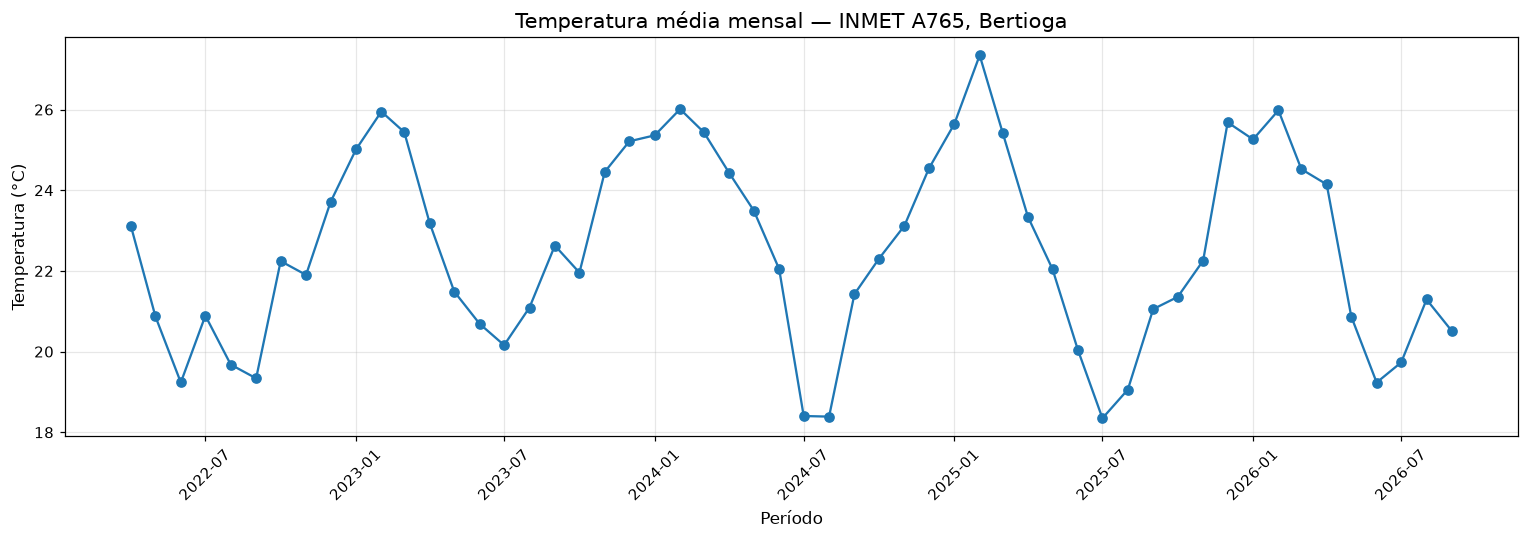

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Calcular a temperatura média mensal
temperatura_mensal = (
    df.groupby(["ano", "mes"])
      ["temperatura_do_ar_bulbo_seco_horaria_c"]
      .agg(
          temperatura_media="mean",
          temperatura_minima="min",
          temperatura_maxima="max",
          medicoes_validas="count"
      )
      .reset_index()
)

# 2. Adicionar informações de cobertura
temperatura_mensal = temperatura_mensal.merge(
    cobertura_mensal[
        ["ano", "mes", "Temperatura (%)"]
    ],
    on=["ano", "mes"],
    how="left"
)

# 3. Selecionar os meses com cobertura >= 90%
temperatura_confiavel = temperatura_mensal[
    temperatura_mensal["Temperatura (%)"] >= 90
].copy()

# 4. Criar datas corretamente
temperatura_confiavel["data"] = pd.to_datetime(
    dict(
        year=temperatura_confiavel["ano"],
        month=temperatura_confiavel["mes"],
        day=1
    )
)

# 5. Visualização dos resultados
display(temperatura_confiavel.head(10))

# 6. Gráfico de temperatura média mensal
plt.figure(figsize=(14, 5))

plt.plot(
    temperatura_confiavel["data"],
    temperatura_confiavel["temperatura_media"],
    marker="o"
)

plt.title("Temperatura média mensal — INMET A765, Bertioga")
plt.xlabel("Período")
plt.ylabel("Temperatura (°C)")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [11]:
# Meses com maiores temperaturas médias

meses_mais_quentes = (
    temperatura_confiavel[
        [
            "ano",
            "mes",
            "temperatura_media",
            "temperatura_maxima",
            "Temperatura (%)"
        ]
    ]
    .sort_values(
        "temperatura_media",
        ascending=False
    )
    .head(10)
)

display(meses_mais_quentes.round(2))

,ano,mes,temperatura_media,temperatura_maxima,Temperatura (%)
49,2025,2,27.34,37.7,100.00
37,2024,2,26.01,36.0,99.86
61,2026,2,25.98,34.3,100.00
25,2023,2,25.95,34.8,100.00
59,2025,12,25.68,34.8,98.25
48,2025,1,25.64,38.1,100.00
26,2023,3,25.44,31.7,100.00
38,2024,3,25.44,38.2,100.00
50,2025,3,25.43,30.8,100.00
36,2024,1,25.36,35.2,99.06


In [12]:
from pathlib import Path
import pandas as pd

# Localizar a pasta principal do projeto
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DESTINO = ROOT / "data" / "processed" / "meteorologia"
DESTINO.mkdir(parents=True, exist_ok=True)

# Resumo das variáveis meteorológicas
resumo_mensal = (
    df.groupby(["codigo_estacao", "estacao", "ano", "mes"])
      .agg(
          temperatura_media=(
              "temperatura_do_ar_bulbo_seco_horaria_c", "mean"
          ),
          temperatura_maxima_observada=(
              "temperatura_do_ar_bulbo_seco_horaria_c", "max"
          ),
          precipitacao_acumulada=(
              "precipitacao_total_horario_mm",
              lambda x: x.sum(min_count=1)
          ),
          umidade_media=(
              "umidade_relativa_do_ar_horaria", "mean"
          ),
          vento_velocidade_media=(
              "vento_velocidade_horaria_m_s", "mean"
          ),
          rajada_maxima=(
              "vento_rajada_maxima_m_s", "max"
          )
      )
      .reset_index()
)

# Adicionar percentuais de cobertura
resumo_mensal = resumo_mensal.merge(
    cobertura_mensal[
        [
            "ano", "mes",
            "Temperatura (%)",
            "Precipitação (%)",
            "Umidade (%)",
            "Vento (%)"
        ]
    ],
    on=["ano", "mes"],
    how="left"
)

# Criar coluna para ordenação temporal no Power BI
resumo_mensal["data_mes"] = pd.to_datetime(
    dict(
        year=resumo_mensal["ano"],
        month=resumo_mensal["mes"],
        day=1
    )
)

arquivo = DESTINO / "meteorologia_resumo_mensal.csv"

resumo_mensal.to_csv(
    arquivo,
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo salvo:", arquivo)

display(resumo_mensal.head())

Arquivo salvo: c:\Users\Lenovo\Desktop\porto-santos\data\processed\meteorologia\meteorologia_resumo_mensal.csv


,codigo_estacao,estacao,ano,mes,temperatura_media,temperatura_maxima_observada,precipitacao_acumulada,umidade_media,vento_velocidade_media,rajada_maxima,Temperatura (%),Precipitação (%),Umidade (%),Vento (%),data_mes
0,A765,BERTIOGA,2021,1,29.191579,35.6,13.0,83.476636,2.077368,9.1,25.54,25.54,14.38,25.54,2021-01-01
1,A765,BERTIOGA,2021,2,28.213131,32.5,36.4,77.538462,1.925000,9.8,29.46,29.46,19.35,29.17,2021-02-01
2,A765,BERTIOGA,2021,3,28.402564,32.2,8.8,79.114865,1.891026,10.0,31.45,31.45,19.89,31.45,2021-03-01
3,A765,BERTIOGA,2021,4,25.422128,32.8,18.2,73.884956,1.709787,13.3,32.64,32.64,31.39,32.64,2021-04-01
4,A765,BERTIOGA,2021,5,23.228311,33.0,6.8,78.426606,1.612785,9.0,29.44,29.44,29.30,29.44,2021-05-01


In [13]:
# Selecionar informações relevantes
colunas_eventos = [
    "data_hora_utc",
    "estacao",
    "codigo_estacao",
    "precipitacao_total_horario_mm",
    "vento_velocidade_horaria_m_s",
    "vento_rajada_maxima_m_s",
    "vento_direcao_horaria_gr_gr",
    "pressao_atmosferica_ao_nivel_da_estacao_horaria_mb"
]

eventos = df[colunas_eventos].copy()

# Selecionar as 20 maiores rajadas registradas
maiores_rajadas = (
    eventos.dropna(subset=["vento_rajada_maxima_m_s"])
    .nlargest(20, "vento_rajada_maxima_m_s")
    .assign(tipo_destaque="Maior rajada")
)

# Selecionar as 20 maiores precipitações horárias
maiores_chuvas = (
    eventos.dropna(subset=["precipitacao_total_horario_mm"])
    .nlargest(20, "precipitacao_total_horario_mm")
    .assign(tipo_destaque="Maior precipitação horária")
)

# Juntar os resultados
eventos_destaque = pd.concat(
    [maiores_rajadas, maiores_chuvas],
    ignore_index=True
)

# Exportar
arquivo_eventos = DESTINO / "meteorologia_eventos_destaque.csv"

eventos_destaque.to_csv(
    arquivo_eventos,
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo salvo:", arquivo_eventos)

display(eventos_destaque)

Arquivo salvo: c:\Users\Lenovo\Desktop\porto-santos\data\processed\meteorologia\meteorologia_eventos_destaque.csv


,data_hora_utc,estacao,codigo_estacao,precipitacao_total_horario_mm,vento_velocidade_horaria_m_s,vento_rajada_maxima_m_s,vento_direcao_horaria_gr_gr,pressao_atmosferica_ao_nivel_da_estacao_horaria_mb,tipo_destaque
0,2022-08-11 00:00:00+00:00,BERTIOGA,A765,0.2,12.5,27.1,272.0,1012.4,Maior rajada
1,2025-12-10 21:00:00+00:00,BERTIOGA,A765,NaN,11.3,27.0,305.0,994.5,Maior rajada
2,2022-08-10 22:00:00+00:00,BERTIOGA,A765,0.4,11.3,26.1,293.0,1010.0,Maior rajada
3,2025-12-10 22:00:00+00:00,BERTIOGA,A765,NaN,11.6,25.8,302.0,995.3,Maior rajada
4,2025-12-10 15:00:00+00:00,BERTIOGA,A765,NaN,2.7,25.3,214.0,998.1,Maior rajada
5,2022-08-11 01:00:00+00:00,BERTIOGA,A765,0.0,9.3,25.0,280.0,1014.3,Maior rajada
6,2022-11-24 23:00:00+00:00,BERTIOGA,A765,28.4,8.7,24.8,267.0,1012.2,Maior rajada
7,2022-11-25 00:00:00+00:00,BERTIOGA,A765,51.6,3.6,24.8,21.0,1013.3,Maior rajada
8,2025-12-10 14:00:00+00:00,BERTIOGA,A765,NaN,4.6,24.4,205.0,998.6,Maior rajada
9,2022-08-10 23:00:00+00:00,BERTIOGA,A765,0.2,9.8,24.1,279.0,1011.7,Maior rajada
